# 01 · Geometry at $q=1$

**Arithmetic Without Addition Lab**  |  Grassmannians, Schubert cells, Weyl groups and the Hecke connection

---

## The conjecture you can calculate

There are $\binom nk$ $k$-element subsets of an $n$-element set. Over the finite field $\mathbb F_q$, the Grassmannian $\mathrm{Gr}(k,n)$ has

$$\#\mathrm{Gr}(k,n)(\mathbb F_q)={n\brack k}_q=\prod_{i=0}^{k-1}\frac{q^{n-i}-1}{q^{k-i}-1}.$$

This number is a *polynomial* in $q$. The surprising observation is that its value at $q=1$ is $\binom nk$. This is a **specialization of a polynomial**, not the literal evaluation of a finite-field formula at a one-element field.

### Experiment A · Enumerate $\mathrm{Gr}(2,4)(\mathbb F_2)$
Every plane has a unique reduced-row-echelon (RREF) matrix. The set of possible pivot columns indexes the Schubert cells; the free matrix entries parametrize an affine space of known dimension.

In [1]:
from collections import Counter
import sympy as sp
import matplotlib.pyplot as plt
from awa_lab.finite_geometry import (rref_matrices, gaussian_polynomial, grassmannian_count,
    schubert_cell_dimensions, flag_poincare_polynomial)
q = sp.symbols('q')
planes = list(rref_matrices(4, 2, 2))
dims = schubert_cell_dimensions(4, 2)
print('RREF planes:', len(planes))
print('Schubert cells (pivots: dimension):', dims)
print('Count reconstructed from cells:', sum(2**d for d in dims.values()))
assert len(planes) == grassmannian_count(4, 2, 2) == 35

RREF planes: 35
Schubert cells (pivots: dimension): {(0, 1): 4, (0, 2): 3, (0, 3): 2, (1, 2): 2, (1, 3): 1, (2, 3): 0}
Count reconstructed from cells: 35


## From cells to $q$-binomials

A Schubert cell of dimension $d$ contributes $q^d$ rational points. Summing over pivot patterns therefore yields a polynomial. Notice that each cell contributes *one* when $q\to1$: only its combinatorial label remains.

Schubert cell polynomial: q**4 + q**3 + 2*q**2 + q + 1
Gaussian binomial: q**4 + q**3 + 2*q**2 + q + 1
At q=1: 6 = number of 2-subsets of {1,2,3,4}


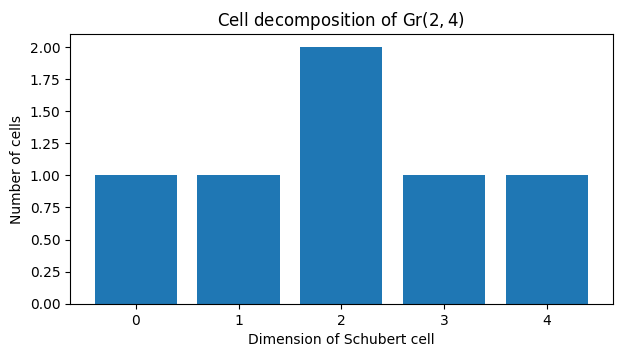

In [2]:
schubert = sp.expand(sum(q**d for d in dims.values()))
gaussian = gaussian_polynomial(4, 2)
print('Schubert cell polynomial:', schubert)
print('Gaussian binomial:', gaussian)
assert sp.expand(schubert-gaussian) == 0
print('At q=1:', gaussian.subs(q,1),'= number of 2-subsets of {1,2,3,4}')
fig, ax = plt.subplots(figsize=(7,3.5))
count_dim = Counter(dims.values())
ax.bar(sorted(count_dim),[count_dim[d] for d in sorted(count_dim)])
ax.set(xlabel='Dimension of Schubert cell', ylabel='Number of cells',
       title=r'Cell decomposition of $\mathrm{Gr}(2,4)$')
ax.set_xticks(sorted(count_dim))
plt.show()

## Experiment B · Weyl groups and the flag variety

For the complete flag variety of $\mathrm{GL}_n$, Bruhat cells are indexed by $S_n$, and the cell corresponding to a permutation $w$ has dimension $\ell(w)$, its inversion number. Hence

$$\#(\mathrm{GL}_n/B)(\mathbb F_q)=\sum_{w\in S_n}q^{\ell(w)}=[n]_q!.$$

At $q=1$ this becomes $n!$. This connects *the combinatorial Weyl group* with finite-field geometry, rather than identifying $\mathbb F_1$ with a literal field.

The same symmetry appears in the Iwahori–Hecke algebra relation $T_s^2=(q-1)T_s+q$: formally at $q=1$, $T_s^2=1$, the Coxeter-group relation for a simple reflection. Our preceding *Hecke Algebras* booklet develops this story.

In [3]:
flag = flag_poincare_polynomial(4)
qfactorial = sp.prod(sum(q**j for j in range(i)) for i in range(1,5))
print('Bruhat polynomial (n=4):', flag)
print('Product of q-integers:', sp.expand(qfactorial))
assert sp.expand(flag-qfactorial)==0
print('q=1:',flag.subs(q,1),'= |S4|')

Bruhat polynomial (n=4): q**6 + 3*q**5 + 5*q**4 + 6*q**3 + 5*q**2 + 3*q + 1
Product of q-integers: q**6 + 3*q**5 + 5*q**4 + 6*q**3 + 5*q**2 + 3*q + 1
q=1: 24 = |S4|


### Investigate (answers intentionally not supplied)

1. Derive the Schubert-cell count of $\mathrm{Gr}(2,5)$ and verify that specialization at $q=1$ gives $\binom52$. Which patterns have maximal and minimal cell dimension?
2. Prove that $\sum_{w\in S_n} q^{\ell(w)}=\prod_{i=1}^n (1+q+\cdots+q^{i-1})$ by inserting $n$ into a permutation of $S_{n-1}$.
3. Which assertions here actually require a chosen definition of $\mathbb F_1$? Which follow from ordinary finite-field geometry alone?

**Precision note.** These examples exhibit a $q\to1$ *principle*, not an equivalence between all $\mathbb F_1$ geometries.